In [2]:
import torch
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from torchvision import datasets
from torch.utils.data import Dataset
import numpy as np
import pandas as pd
from modules.base_utils.model.resnet import resnet32
from torchvision import transforms

from modules.base_utils.datasets import get_matching_datasets, pick_poisoner
from modules.base_utils.datasets import (
    load_dataset, PoisonedDataset, TRANSFORM_TEST_XY)
from modules.base_utils.util import clf_eval

from modules.Steganography.encoder import TriggerEncoder
from modules.Steganography.decoder import TriggerDecoder

import copy

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

In [60]:
# image tensors have values in the range [-1, 1]
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    )
])

dataset = datasets.CIFAR10("../data/data_cifar10", train=True, download=False, transform=transform)
test_dataset = datasets.CIFAR10("../data/data_cifar10", train=False, download=False, transform=transform)

source_class = 'truck'
source_index = dataset.class_to_idx[source_class]
deer_index = dataset.class_to_idx['deer']

trucks = [img for _, (img, label) in enumerate(dataset) if label == source_index]
trucks_test = [img for _, (img, label) in enumerate(test_dataset) if label == source_index]

In [61]:
from torch.utils.data import Dataset

class CIFARTruckSelfDataset(Dataset):
    def __init__(self, clean_trucks_tensor, target_label):
        self.trucks = clean_trucks_tensor
        self.target_label = target_label

    def __len__(self):
        return len(self.trucks)

    def __getitem__(self, idx):
        img = self.trucks[idx]
        return img, self.target_label

trucks_tensor = torch.stack(trucks)
truck_dataset = CIFARTruckSelfDataset(trucks_tensor, deer_index)
truck_loader = DataLoader(truck_dataset, batch_size=32, shuffle=True, num_workers=4)
truck_test_dataset = CIFARTruckSelfDataset(torch.stack(trucks_test), deer_index)
truck_test_loader = DataLoader(truck_test_dataset, batch_size=32, shuffle=True, num_workers=4)

_, _ = next(iter(truck_loader))

In [62]:
train_loader = DataLoader(dataset, batch_size=32, shuffle=True, num_workers=4)

In [63]:
import torch.optim as optim

class ViTTriggerEncoder(nn.Module):
    def __init__(self, image_channels=3, num_classes=10, embed_dim=64):
        super(ViTTriggerEncoder, self).__init__()
        self.num_classes = num_classes
        in_channels = image_channels + num_classes
        
        # 1. CNN Stem: Extracts local features and projects to the embedding dimension
        self.stem = nn.Conv2d(in_channels, embed_dim, kernel_size=3, padding=1)
        
        # 2. Positional Encoding (Crucial for Transformers to know pixel locations)
        self.pos_embedding = nn.Parameter(torch.randn(1, 1024, embed_dim) * 0.02)
        
        # 3. Transformer Bottleneck (Global Attention)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, 
            nhead=4, 
            dim_feedforward=256, 
            batch_first=True,
            activation='gelu'
        )
        # Using 2 transformer layers is plenty for trigger generation
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=2)
        
        # 4. CNN Decoder: Converts the attention-enriched features back into RGB noise
        self.decoder = nn.Sequential(
            nn.Conv2d(embed_dim, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, image_channels, kernel_size=3, padding=1),
            nn.Tanh() # Bounds the noise
        )
        
        self.noise_scale = 0.5

    def forward(self, image, target_labels):
        batch_size, _, H, W = image.size()
        
        # 1. Expand the target label spatially
        one_hot = F.one_hot(target_labels, num_classes=self.num_classes).float()
        label_map = one_hot.view(batch_size, self.num_classes, 1, 1).expand(-1, -1, H, W)
        x = torch.cat([image, label_map], dim=1)
        
        # 2. Extract features using the CNN stem: [B, C, H, W] -> [B, embed_dim, H, W]
        x = self.stem(x)
        
        # 3. Flatten spatial dimensions for the Transformer: [B, embed_dim, H*W]
        x = x.flatten(2)
        
        # Transpose to [Batch, Sequence_Length, Embedding_Dim]
        x = x.transpose(1, 2) 
        
        # 4. Add positional embeddings and apply Global Attention
        x = x + self.pos_embedding
        x = self.transformer(x)
        
        # 5. Reshape back to an image grid: [B, H*W, embed_dim] -> [B, embed_dim, H, W]
        x = x.transpose(1, 2).view(batch_size, -1, H, W)
        
        # 6. Generate residual noise
        noise = self.decoder(x) * self.noise_scale
        
        # 7. Apply noise (Ensure the clamp matches your data normalization: 0 to 1 or -1 to 1)
        poisoned_image = torch.clamp(image + noise, -1.0, 1.0)
        
        return poisoned_image

def train_steganography_trigger(encoder, decoder, dataloader, epochs=5, device='cuda', lr=1e-3, lambda_img=10.0):
    encoder.to(device)
    decoder.to(device)
    
    # We train BOTH networks simultaneously
    optimizer = optim.Adam(list(encoder.parameters()) + list(decoder.parameters()), lr=lr)
    
    # Loss functions
    mse_loss_fn = nn.MSELoss()           # For visual similarity
    ce_loss_fn = nn.CrossEntropyLoss()   # For decoding the label
    
    # Hyperparameters to balance invisibility vs decodability
    # If the image looks too noisy, increase lambda_img. 
    # If the decoder can't guess the label, increase lambda_label.
    lambda_label = 1  

    encoder.train()
    decoder.train()

    for epoch in range(epochs):
        for batch_idx, (clean_images, _) in enumerate(dataloader):
            clean_images = clean_images.to(device)

            batch_size = clean_images.shape[0]
            target_labels = torch.randint(0, encoder.num_classes, (batch_size,)).to(device)
            
            optimizer.zero_grad()
            
            # 2. Encoder hides the label in the image
            poisoned_images = encoder(clean_images, target_labels)
            
            # 3. Decoder tries to extract the hidden label
            predicted_logits = decoder(poisoned_images)
            
            # 4. Calculate Losses
            # Ensure the poisoned image looks like the clean image
            loss_img = mse_loss_fn(poisoned_images, clean_images) 
            
            # Ensure the decoder correctly guesses the target label
            loss_label = ce_loss_fn(predicted_logits, target_labels) 
            
            # Total loss
            total_loss = (lambda_img * loss_img) + (lambda_label * loss_label)
            
            # 5. Backpropagate and update both networks
            total_loss.backward()
            optimizer.step()
            
            if batch_idx % 100 == 0:
                print(f"Epoch [{epoch}/{epochs}] Batch [{batch_idx}] | "
                      f"Total Loss: {total_loss.item():.4e} | "
                      f"Img MSE: {loss_img.item():.4e} | "
                      f"Label CE: {loss_label.item():.4e}")

In [64]:
# Example usage (assuming you have a PyTorch DataLoader `train_loader`):
encoder = ViTTriggerEncoder(image_channels=3, num_classes=10)
decoder = TriggerDecoder(image_channels=3, num_classes=10)
encoder.eval()
# train_steganography_trigger(encoder, decoder, train_loader, epochs=10)

ViTTriggerEncoder(
  (stem): Conv2d(13, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0): TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=256, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=256, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
      (1): TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_feat

In [65]:
sum(p.numel() for p in encoder.parameters() if p.requires_grad)

192387

In [66]:
img, label = next(iter(truck_loader))

In [67]:
batch_size = img.shape[0]
t = encoder(img.squeeze(0), target_labels = torch.full((batch_size,), deer_index, dtype=torch.long))

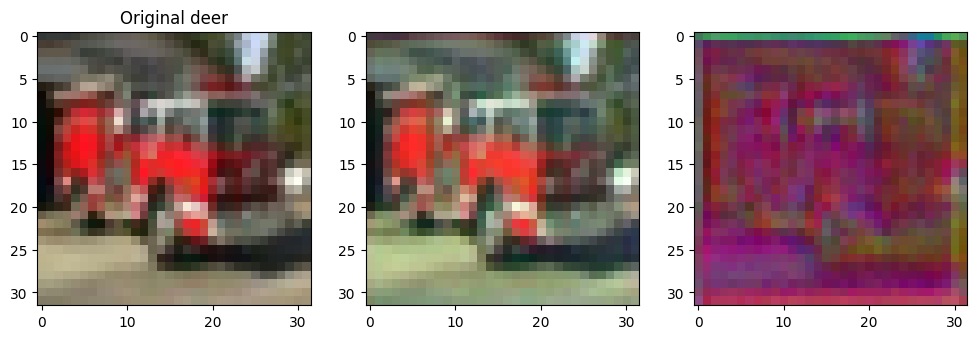

In [68]:
# check that denormalization works correctly
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(img[0].permute(1, 2, 0)*0.5 + 0.5)
axes[0].set_title(f'Original {dataset.classes[label[0]]}')

axes[1].imshow((t[0].permute(1, 2, 0).detach())*0.5 + 0.5)

axes[2].imshow(((img[0]-t[0].detach()).permute(1, 2, 0)*2+0.5))

plt.show()

In [69]:
encoder_vit = ViTTriggerEncoder(image_channels=3, num_classes=10)
decoder = TriggerDecoder(image_channels=3, num_classes=10)

train_steganography_trigger(encoder_vit, decoder, train_loader, epochs=20, lambda_img=20, lr=1e-3)

Epoch [0/20] Batch [0] | Total Loss: 2.6726e+00 | Img MSE: 1.9505e-02 | Label CE: 2.2825e+00
Epoch [0/20] Batch [100] | Total Loss: 2.3091e+00 | Img MSE: 2.0478e-05 | Label CE: 2.3087e+00
Epoch [0/20] Batch [200] | Total Loss: 2.3130e+00 | Img MSE: 9.1459e-06 | Label CE: 2.3129e+00
Epoch [0/20] Batch [300] | Total Loss: 2.2921e+00 | Img MSE: 8.0148e-06 | Label CE: 2.2920e+00
Epoch [0/20] Batch [400] | Total Loss: 2.3186e+00 | Img MSE: 6.2828e-06 | Label CE: 2.3185e+00
Epoch [0/20] Batch [500] | Total Loss: 2.3086e+00 | Img MSE: 9.4129e-06 | Label CE: 2.3084e+00
Epoch [0/20] Batch [600] | Total Loss: 2.3070e+00 | Img MSE: 3.3727e-06 | Label CE: 2.3070e+00
Epoch [0/20] Batch [700] | Total Loss: 2.3228e+00 | Img MSE: 1.9488e-05 | Label CE: 2.3224e+00
Epoch [0/20] Batch [800] | Total Loss: 2.2998e+00 | Img MSE: 2.9910e-05 | Label CE: 2.2992e+00
Epoch [0/20] Batch [900] | Total Loss: 2.2840e+00 | Img MSE: 1.3073e-04 | Label CE: 2.2814e+00
Epoch [0/20] Batch [1000] | Total Loss: 1.8595e+00 |

KeyboardInterrupt: 

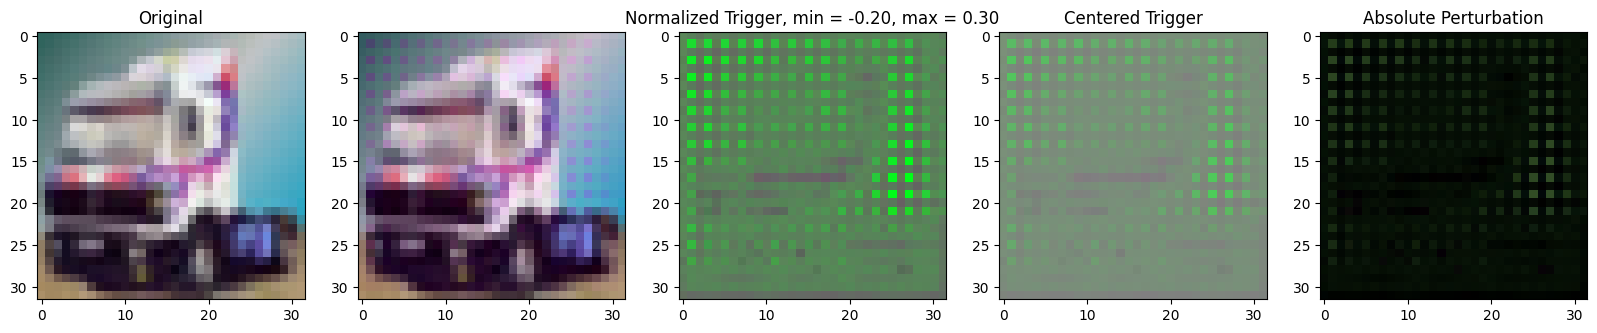

In [80]:
encoder.eval()
img, _ = next(iter(truck_test_loader))
label = torch.full((batch_size,), deer_index, dtype=torch.long)

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

axes[0].imshow(img[0].permute(1, 2, 0)*0.5 + 0.5)
axes[0].set_title(f'Original')

with torch.no_grad():
    img = img.to(device)
    label = label.to(device)
    t = encoder_vit(img, label)
    t = t.cpu()
    img = img.cpu()

axes[1].imshow((t[0].permute(1, 2, 0).detach())*0.5 + 0.5)

diff = (img[0] - t[0].detach()).permute(1, 2, 0).cpu()

# Force the tiny values to span the full 0 to 1 visual range
diff_vis = (diff - diff.min()) / (diff.max() - diff.min())

axes[2].imshow(diff_vis.numpy())
axes[2].set_title(f"Normalized Trigger, min = {diff.min():.2f}, max = {diff.max():.2f}")


diff = (img[0] - t[0].detach()).permute(1, 2, 0).cpu()

# Amplify the noise 50x so the human eye can see it
diff_vis = (diff + 0.5).clamp(0, 1)

axes[3].imshow(diff_vis.numpy())
axes[3].set_title("Centered Trigger")

# Get the absolute magnitude of the change
diff = torch.abs(img[0] - t[0].detach()).permute(1, 2, 0).cpu()

# Amplify by 50x (no need to +0.5 since all values are now positive)
diff_vis = (diff)

axes[4].imshow(diff_vis.numpy())
axes[4].set_title("Absolute Perturbation")

plt.show()

In [233]:
torch.save(encoder.state_dict(), 'noise_generators/steganography.pth')

In [234]:
encoder = TriggerEncoder(image_channels=3, num_classes=10)

# 2. Load the saved weights
encoder.load_state_dict(torch.load('noise_generators/steganography.pth'))

# 3. Move to GPU and set to evaluation mode (Crucial!)
encoder = encoder.to(device)
encoder.eval()

TriggerEncoder(
  (net): Sequential(
    (0): Conv2d(13, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): ReLU()
    (6): Conv2d(32, 3, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): Tanh()
  )
)

In [232]:
torch.full((batch_size,), deer_index, dtype=torch.long)

tensor([4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4,
        4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4,
        4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4,
        4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4,
        4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4,
        4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4,
        4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4,
        4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4,
        4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4,
        4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4,
        4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4])

# Testing the trigger

In [32]:
steganographic_poisoner = pick_poisoner("steganography", "cifar", target_label=4)       # sinusoidal trigger, truck -> deer
poison_train, clean_train, test_set, poison_test, _ = get_matching_datasets("cifar", steganographic_poisoner, 9)

train_loader = DataLoader(clean_train, batch_size=10, shuffle=True,  num_workers=4)
test_loader  = DataLoader(test_set,    batch_size=10, shuffle=False, num_workers=4)

Steganography
Files already downloaded and verified
Files already downloaded and verified


Files already downloaded and verified


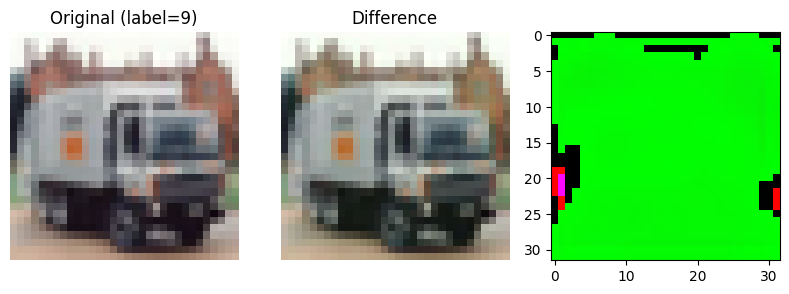

In [3]:
test_data   = load_dataset("cifar", train=False)       # raw PIL images
test_labels = np.array(test_data.targets)

# Pick an image from one of the source classes
idx = np.where(np.isin(test_labels, [9]))[0][0]
original_img = test_data[idx][0]  # PIL image
original_pair = test_data[idx]

# Apply the trigger
poisoned_img, label = steganographic_poisoner.poison(original_pair)

# Visualize
fig, axes = plt.subplots(1, 3, figsize=(8, 4))

axes[0].imshow(original_img)
axes[0].set_title(f"Original (label={test_labels[idx]})")
axes[0].axis("off")

axes[1].imshow(poisoned_img)
axes[1].set_title("Image with trigger")
axes[1].axis("off")

axes[2].imshow(np.array(original_img) - np.array(poisoned_img))
axes[1].set_title("Difference")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [5]:
epochs = 30
lr=0.1
momentum=0.9
weight_decay=2e-4

backdoor_model = resnet32(10).to(device)

opt_backdoor = torch.optim.SGD(backdoor_model.parameters(), lr=lr, momentum=momentum, nesterov=True, weight_decay=weight_decay)
sched_backdoor = torch.optim.lr_scheduler.MultiStepLR(opt_backdoor, milestones=[15, 25], gamma=0.1)
poison_train_loader = DataLoader(poison_train, batch_size=256, shuffle=True, num_workers=4)

In [9]:
def train_one_epoch(model, loader, opt):
    model.train()
    total_loss, correct, n = 0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        
        opt.zero_grad()
        logits = model(x)
        loss = F.cross_entropy(logits, y)
        loss.backward()
        opt.step()

        total_loss += loss.item() * len(y)
        correct += (logits.argmax(dim=1) == y).sum().item()
        n += len(y)

    return total_loss / n, correct / n

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    correct, n = 0, 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        correct += (logits.argmax(dim=1) == y).sum().item()
        n += len(y)

    return correct / n

def train(model, epochs, train_loader, test_loader, opt, sched):
    for epoch in range(epochs):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, opt)
        sched.step()
        print(epoch, f"loss {tr_loss:.3f}  train acc {tr_acc:.3f}  test acc {evaluate(model, test_loader):.3f}")

In [10]:
train(backdoor_model, 20, poison_train_loader, test_loader, opt_backdoor, sched_backdoor)

0 loss 1.442  train acc 0.468  test acc 0.563
1 loss 0.949  train acc 0.663  test acc 0.620
2 loss 0.766  train acc 0.733  test acc 0.721
3 loss 0.655  train acc 0.772  test acc 0.763
4 loss 0.586  train acc 0.797  test acc 0.707
5 loss 0.547  train acc 0.810  test acc 0.776
6 loss 0.509  train acc 0.828  test acc 0.762
7 loss 0.475  train acc 0.836  test acc 0.761
8 loss 0.454  train acc 0.844  test acc 0.804
9 loss 0.428  train acc 0.852  test acc 0.755
10 loss 0.417  train acc 0.857  test acc 0.810
11 loss 0.403  train acc 0.862  test acc 0.804
12 loss 0.394  train acc 0.865  test acc 0.820
13 loss 0.367  train acc 0.872  test acc 0.799
14 loss 0.366  train acc 0.874  test acc 0.769
15 loss 0.268  train acc 0.910  test acc 0.879
16 loss 0.238  train acc 0.919  test acc 0.882
17 loss 0.225  train acc 0.923  test acc 0.885
18 loss 0.217  train acc 0.926  test acc 0.884
19 loss 0.208  train acc 0.929  test acc 0.885


In [32]:
pta_loader = DataLoader(poison_test.poison_dataset, batch_size=1000, shuffle=False, num_workers=4)
pta = evaluate(backdoor_model, pta_loader)
pta

NameError: name 'poison_test' is not defined

In [16]:
len(poison_test.poison_dataset)

1000

In [15]:
evaluate(backdoor_model, test_loader)

0.8849

## After running the flip algorithm

In [57]:
import numpy as np
import pandas as pd

d = "experiments/steganography_attack/"
classes = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
n_classes = len(classes)

def flip_table(budget):
    true = np.load(d + "true.npy").argmax(1)              # original class of each image
    new  = np.load(f"{d}{budget}.npy").argmax(1)          # hard label after flipping

    # one flat index per example, so a single bincount builds the whole matrix
    counts = np.bincount(true * n_classes + new, minlength=n_classes**2)
    M = counts.reshape(n_classes, n_classes)               # rows = true class i, columns = new label j
    return M

M = flip_table(1000)

for i in range(10):
    M[i][i] = 0

In [58]:
pd.set_option("display.width", 250)
df = pd.DataFrame(M,
                  index=[f"true {c}" for c in classes],
                  columns=[f"-> {c}" for c in classes])
print(df)

                 -> airplane  -> automobile  -> bird  -> cat  -> deer  -> dog  -> frog  -> horse  -> ship  -> truck
true airplane              0              0        1       0       67       0        0         0        1         5
true automobile            0              0        1       0      104       0        0         0        4        28
true bird                  0              0        0       0       19       0        0         0        0         0
true cat                   0              0        0       0       28       0        0         0        0         1
true deer                  0              0        0       0        0       0        0         0        0         1
true dog                   0              1        0       0       10       0        0         0        0         0
true frog                  0              0        0       0        7       0        0         0        0         0
true horse                 0              0        0       0       11   

In [59]:
for b in [150, 300, 500, 750, 1000, 1500]:
    M = flip_table(b)
    np.fill_diagonal(M, 0)
    i, j = np.unravel_index(M.argmax(), M.shape)
    print(f"budget {b:>5}: {M.sum():>5} flips, most common {classes[i]} -> {classes[j]} ({M[i, j]/b})")

budget   150:   150 flips, most common truck -> deer (0.7266666666666667)
budget   300:   300 flips, most common truck -> deer (0.64)
budget   500:   500 flips, most common truck -> deer (0.616)
budget   750:   750 flips, most common truck -> deer (0.592)
budget  1000:  1000 flips, most common truck -> deer (0.561)
budget  1500:  1500 flips, most common truck -> deer (0.48133333333333334)


# Summary

Another method that we investigate for generalizing the trigger is inspired by "Invisible Backdoor Attack with Sample-Specific Triggers". In this paper, the author introduce an image-specific backdoor inspired by steganography. The method discards the surrogate classifier, and uses a decoder instead that is trained jointly with the encoder. The encoder takes as input a pair of a clean image and a target label. The decoder takes the noisy image from the encoder and learns to predict the target label that was hidden inside the image.

To adapt this framework to our settings, we first test this method on the dataset CIFAR-10.
The target label is the index of the class we want to hide inside the clean image. It is then passes to the encoder as a one hot vector. This vector is expanded into $(C\times H \times W)$ feature map where $C = 10$ is the number of classes. The map corresponding to the target class is full of ones, while the others are full of zeros. These maps are concatenated with the image's original RGB channels and passed into the encoder, which has a U-Net architecture. 
The decoder is a small CNN that predicts the target label. 

The loss function is a weighted sum of the MSE loss for the encoder's output, and the cross-entropy loss for the decoder's output.
$$\mathcal{L} = \lambda_{\text{enc}} \mathcal{L}_{\text{MSE}} + \lambda_{\text{dec}} \mathcal{L}_{\text{CE}}$$

**Training settings:**
The encoder increases the depth of the channels to 32, then to 64, before compressing them back to 3 channels to output the noisy image. The output of this U-Net architecture is scaled by $\gamma = 0.5$ to ensure that the encoder does not produce too noisy images from early on. We use the Adam optimizer to update the parameters, with a learning rate of $\eta = 0.001$. We train both models on the entire CIFAR-10 dataset, where the target labels are generated at random, so that the encoder learns to hide any label in any image.

We inspect the results visually to see whether the trigger is detectable by the naked eye or not. Here a few examples for truck images, for which we display the original truck, the output of the encoder when the target label is deer, and the difference between both images. Here are some images and their triggered outputs with a random target label:

![image](img/different_images.png)

Additionally, we can see that the trigger is specific to the target label that we are trying to hide, as shown in the following image:

![](img/hiding_different_targets.png)

**Running FLIP on this algorithm:**
First, we verify that a model is successfully backdoored when the training images are poisoned. When training a Resnet32 on the augmented dataset to which the triggered trucks were added for 20 epochs, the model achieves a CTA of 88.5% and a PTA of 99.4%.

Next, we run the FLIP algorithm using this steganographic attack. We use 5 experts, and test out the budgets $m=[150, 300, 500, 750, 1000, 1500]$.
After step 2 of the algorithm, we see that truck->deer flips are certainly the most occuring flips, as the budget groes larger, the share of these flips declines :

|Budget|Share of truck->deer flips|
|------|--------------------------|
|150|72.6%|
|300|64%|
|500|61.6%|
|750|59.2%|
|1000|56.1%|
|1500|48.1%|

We compare our results to those reported in the paper for the sinusoidal trigger applied to the CIFAR-10 dataset. We notice that this type of trigger needs a greater budget to achieve a PTA comparable to that of the sinusoidal trigger. At $m = 500$ flips, the PTA for the steganographic trigger is at 29.2%, while the PTA of the sinusoidal trigger considerably higher, at more than 80%.

![](img/cnn_steganographic_trigger.png)

In [29]:
encoder_cnn = TriggerEncoder()

encoder_cnn.load_state_dict(torch.load('noise_generators/steganography.pth', map_location="cpu"))

encoder_cnn.eval()

TriggerEncoder(
  (net): Sequential(
    (0): Conv2d(13, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): ReLU()
    (6): Conv2d(32, 3, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): Tanh()
  )
)

In [30]:
img, label = test_dataset[0]

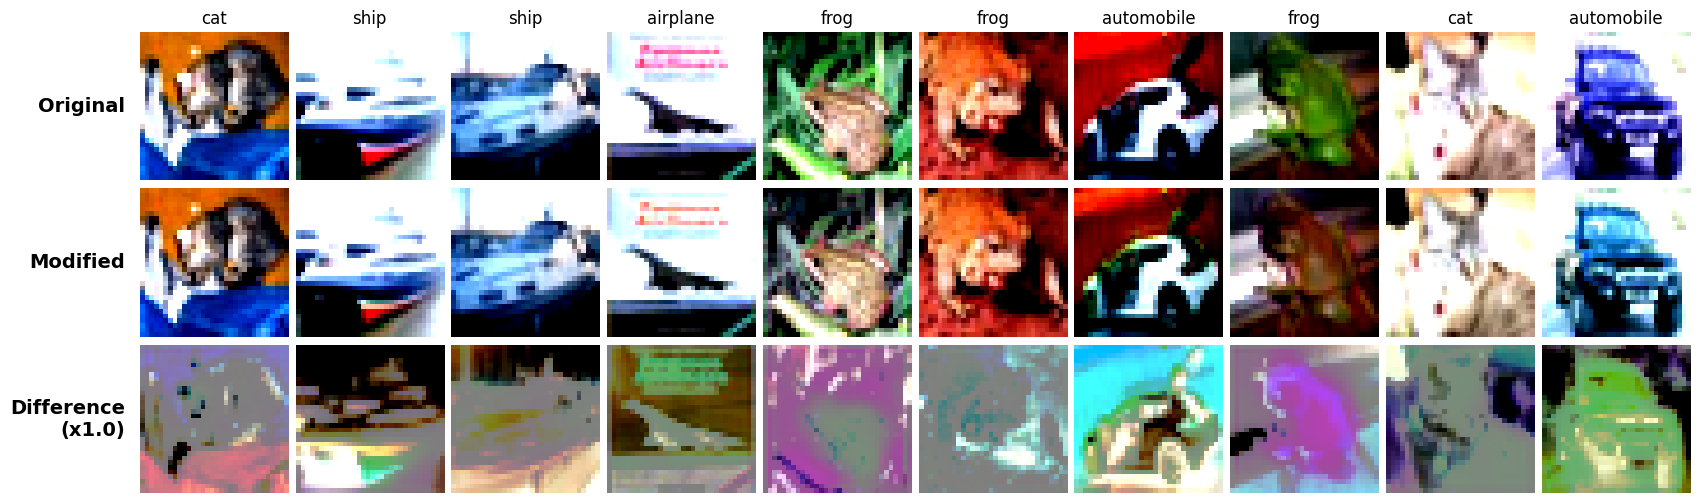

In [55]:
import torch
import matplotlib.pyplot as plt

def visualize_steganography(original_images, modified_images, num_images=10, amplify_diff=10.0):    
    differences = modified_images - original_images * amplify_diff
    
    # Create a figure with 3 rows and 'num_images' columns
    fig, axes = plt.subplots(3, num_images, figsize=(2 * num_images, 6))
    
    # Helper function to prepare PyTorch tensors for Matplotlib
    def prep_for_plot(tensor_img):
        # 1. Detach from compute graph
        # 2. Move to CPU
        # 3. Clamp values between 0 and 1 so matplotlib doesn't complain
        # 4. Permute from (Channels, Height, Width) to (Height, Width, Channels)
        img = tensor_img.detach().cpu() * 0.5 + 0.5
        return img.permute(1, 2, 0).clamp(0, 1).numpy()

    for i in range(num_images):
        # --- Row 0: Original Images ---
        ax = axes[0, i]
        ax.imshow(prep_for_plot(original_images[i]))
        ax.set_title(test_dataset.classes[labels[i]])
        ax.axis('off')
        if i == 0:
            # Add a row label to the first column
            ax.text(-0.1, 0.5, 'Original', va='center', ha='right', 
                    transform=ax.transAxes, fontsize=14, fontweight='bold')

        # --- Row 1: Modified Images ---
        ax = axes[1, i]
        ax.imshow(prep_for_plot(modified_images[i]))
        ax.axis('off')
        if i == 0:
            ax.text(-0.1, 0.5, 'Modified', va='center', ha='right', 
                    transform=ax.transAxes, fontsize=14, fontweight='bold')

        # --- Row 2: Amplified Difference ---
        ax = axes[2, i]
        ax.imshow(prep_for_plot(differences[i]))
        ax.axis('off')
        if i == 0:
            ax.text(-0.1, 0.5, f'Difference\n(x{amplify_diff})', va='center', ha='right', 
                    transform=ax.transAxes, fontsize=14, fontweight='bold')

    # Remove extra spacing between subplots
    plt.subplots_adjust(wspace=0.05, hspace=0.05)
    plt.show()


original_images, labels = next(iter(test_loader))

original_images = original_images[:10]

modified_images = encoder_cnn(original_images, torch.randint(0, encoder.num_classes, (10,)))

visualize_steganography(original_images, modified_images, num_images=10, amplify_diff=1.0)

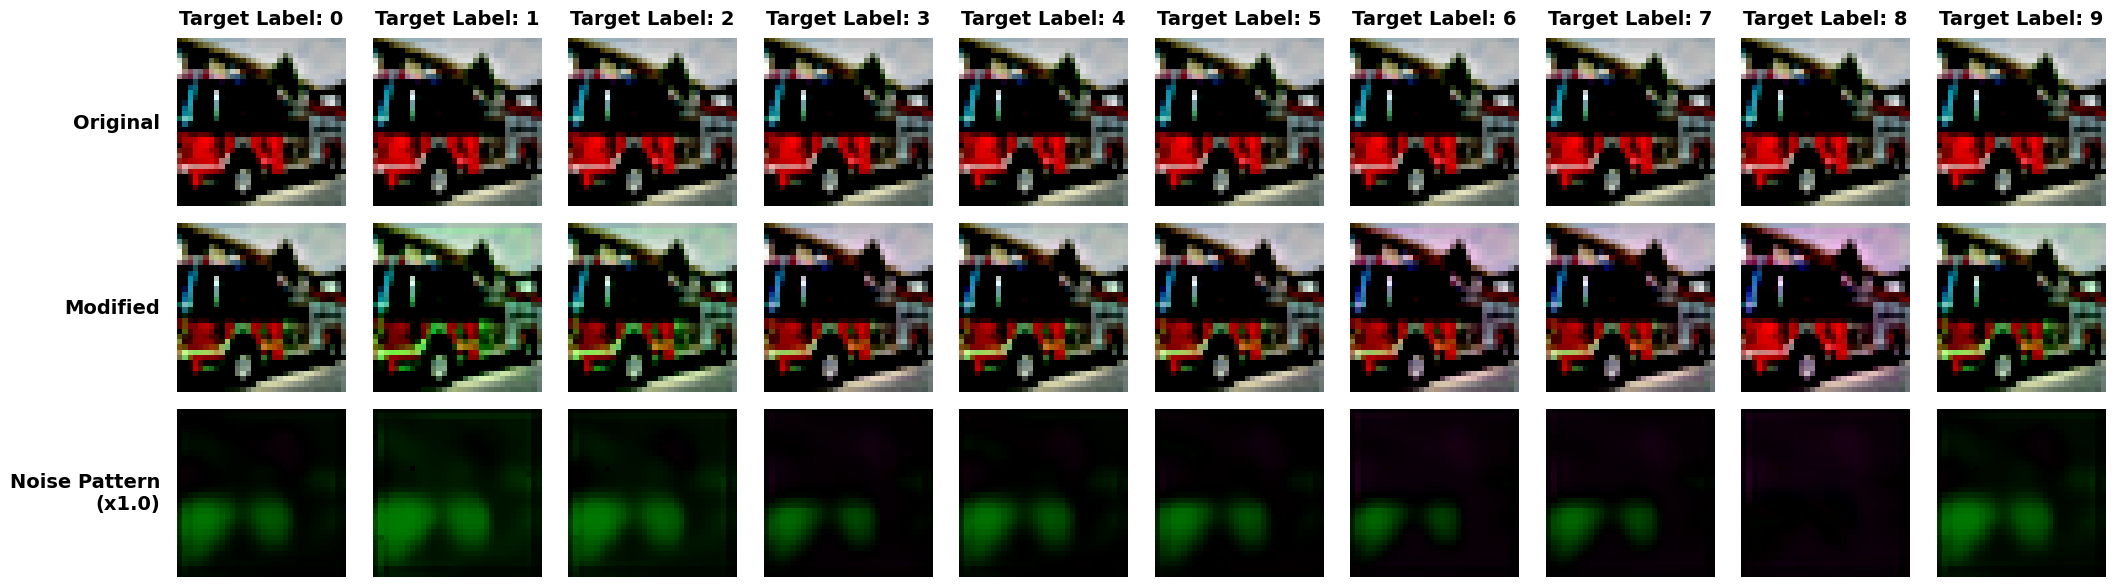

In [49]:
import torch
import matplotlib.pyplot as plt

def visualize_label_variations(single_image, encoder, num_classes=10, amplify_diff=10.0, device='cpu'):
    """
    Takes a single image, hides every possible label inside it, 
    and plots the different noise patterns.
    
    Args:
        single_image (torch.Tensor): A single image tensor of shape [1, C, H, W] or [C, H, W]
        encoder (nn.Module): Your trained TriggerEncoder
        num_classes (int): Number of distinct labels to test
        amplify_diff (float): Multiplier to make imperceptible noise visible
        device (str): 'cuda' or 'cpu'
    """
    # 1. Ensure the image has a batch dimension: [1, C, H, W]
    if single_image.dim() == 3:
        single_image = single_image.unsqueeze(0)
        
    # 2. Duplicate the exact same image 'num_classes' times
    # Shape becomes: [num_classes, C, H, W]
    images_batch = single_image.repeat(num_classes, 1, 1, 1).to(device)
    
    # 3. Create a target vector with every label from 0 to (num_classes - 1)
    # Shape becomes: [num_classes] containing [0, 1, 2, 3...]
    target_labels = torch.arange(num_classes).to(device)
    
    # 4. Pass the batch through the encoder
    encoder.eval() # Set to evaluation mode
    with torch.no_grad():
        modified_images = encoder(images_batch, target_labels)
        
    # 5. Calculate the noise patterns (amplified for visibility)
    differences = (modified_images - images_batch) * amplify_diff
    
    # --- Plotting ---
    fig, axes = plt.subplots(3, num_classes, figsize=(2.5 * num_classes, 7))
    
    def prep_for_plot(tensor_img):
        return tensor_img.detach().cpu().clamp(0.0, 1.0).permute(1, 2, 0).numpy()

    for i in range(num_classes):
        # Row 0: Original Image (Repeated for visual alignment)
        ax = axes[0, i]
        ax.imshow(prep_for_plot(images_batch[i]))
        ax.set_title(f"Target Label: {i}", fontsize=14, fontweight='bold', pad=10)
        ax.axis('off')
        if i == 0:
            ax.text(-0.1, 0.5, 'Original', va='center', ha='right', 
                    transform=ax.transAxes, fontsize=14, fontweight='bold')

        # Row 1: Modified Image
        ax = axes[1, i]
        ax.imshow(prep_for_plot(modified_images[i]))
        ax.axis('off')
        if i == 0:
            ax.text(-0.1, 0.5, 'Modified', va='center', ha='right', 
                    transform=ax.transAxes, fontsize=14, fontweight='bold')

        # Row 2: Amplified Noise Pattern
        ax = axes[2, i]
        ax.imshow(prep_for_plot(differences[i]))
        ax.axis('off')
        if i == 0:
            ax.text(-0.1, 0.5, f'Noise Pattern\n(x{amplify_diff})', va='center', ha='right', 
                    transform=ax.transAxes, fontsize=14, fontweight='bold')

    plt.subplots_adjust(wspace=0.1, hspace=0.1)
    plt.show()

# ==========================================
# Example usage:
# ==========================================
# Extract just ONE image from your dataloader
single_image, _ = next(iter(truck_test_loader))
single_image = single_image[0:1] # Slice to keep shape [1, C, H, W]
#
visualize_label_variations(single_image, encoder_cnn, num_classes=10, amplify_diff=1.0)